In [54]:
import pandas as pd 
import numpy as np 
import seaborn as sns 
import matplotlib.pyplot as plt 
from pathlib import Path
from sklearn.preprocessing import LabelEncoder


In [22]:
display(full_df.head(5))

,Unnamed: 0,accelerometer_right_foot_x,accelerometer_right_foot_y,accelerometer_right_foot_z,gyroscope_right_foot_x,gyroscope_right_foot_y,gyroscope_right_foot_z,accelerometer_right_shin_x,accelerometer_right_shin_y,accelerometer_right_shin_z,...,gyroscope_left_shin_z,accelerometer_left_thigh_x,accelerometer_left_thigh_y,accelerometer_left_thigh_z,gyroscope_left_thigh_x,gyroscope_left_thigh_y,gyroscope_left_thigh_z,EMG_right,EMG_left,activity
0,0,-7868,-1336,13400,-28,26,-24,-14920,-240,-6800,...,18,-5696,2088,16016,26,-3,9,120,129,sitting
1,1,-7956,-1384,13468,-20,28,-22,-14824,-216,-6928,...,12,-5608,2224,16184,20,-3,7,120,128,sitting
2,2,-7892,-1348,13492,-18,24,-26,-14816,-144,-6808,...,13,-5512,2168,16216,21,-7,9,120,129,sitting
3,3,-7856,-1352,13504,-16,23,-21,-14984,-56,-7200,...,17,-5552,2184,16048,20,-3,4,121,128,sitting
4,4,-7896,-1356,13440,-13,26,-21,-14944,-280,-6920,...,16,-5536,2032,16040,21,-9,7,121,128,sitting


In [25]:
# Load all HuGaDB CSV files
from pathlib import Path
import glob

data_dir = Path("../data/hugadb-human-gait-database")
csv_files = sorted(data_dir.glob("HuGaDB_v2_*.csv"))

print(f"Found {len(csv_files)} CSV files")

# Load and concatenate all CSV files
dfs = [pd.read_csv(f) for f in csv_files]
full_df = pd.concat(dfs, ignore_index=True)

print(f"Combined shape: {full_df.shape}")
print(f"Columns: {full_df.columns.tolist()}")


Found 364 CSV files
Combined shape: (1137279, 40)
Columns: ['Unnamed: 0', 'accelerometer_right_foot_x', 'accelerometer_right_foot_y', 'accelerometer_right_foot_z', 'gyroscope_right_foot_x', 'gyroscope_right_foot_y', 'gyroscope_right_foot_z', 'accelerometer_right_shin_x', 'accelerometer_right_shin_y', 'accelerometer_right_shin_z', 'gyroscope_right_shin_x', 'gyroscope_right_shin_y', 'gyroscope_right_shin_z', 'accelerometer_right_thigh_x', 'accelerometer_right_thigh_y', 'accelerometer_right_thigh_z', 'gyroscope_right_thigh_x', 'gyroscope_right_thigh_y', 'gyroscope_right_thigh_z', 'accelerometer_left_foot_x', 'accelerometer_left_foot_y', 'accelerometer_left_foot_z', 'gyroscope_left_foot_x', 'gyroscope_left_foot_y', 'gyroscope_left_foot_z', 'accelerometer_left_shin_x', 'accelerometer_left_shin_y', 'accelerometer_left_shin_z', 'gyroscope_left_shin_x', 'gyroscope_left_shin_y', 'gyroscope_left_shin_z', 'accelerometer_left_thigh_x', 'accelerometer_left_thigh_y', 'accelerometer_left_thigh_z', 'g

In [27]:
df = full_df 

In [29]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1137279 entries, 0 to 1137278
Data columns (total 40 columns):
 #   Column                       Non-Null Count    Dtype
---  ------                       --------------    -----
 0   Unnamed: 0                   1137279 non-null  int64
 1   accelerometer_right_foot_x   1137279 non-null  int64
 2   accelerometer_right_foot_y   1137279 non-null  int64
 3   accelerometer_right_foot_z   1137279 non-null  int64
 4   gyroscope_right_foot_x       1137279 non-null  int64
 5   gyroscope_right_foot_y       1137279 non-null  int64
 6   gyroscope_right_foot_z       1137279 non-null  int64
 7   accelerometer_right_shin_x   1137279 non-null  int64
 8   accelerometer_right_shin_y   1137279 non-null  int64
 9   accelerometer_right_shin_z   1137279 non-null  int64
 10  gyroscope_right_shin_x       1137279 non-null  int64
 11  gyroscope_right_shin_y       1137279 non-null  int64
 12  gyroscope_right_shin_z       1137279 non-null  int64
 13  accelerometer_right_thi

In [32]:
df.nunique()

Unnamed: 0                     12472
accelerometer_right_foot_x     15098
accelerometer_right_foot_y     16256
accelerometer_right_foot_z     16208
gyroscope_right_foot_x         50849
gyroscope_right_foot_y         61781
gyroscope_right_foot_z         60742
accelerometer_right_shin_x     13355
accelerometer_right_shin_y     14726
accelerometer_right_shin_z     15301
gyroscope_right_shin_x         55033
gyroscope_right_shin_y         62001
gyroscope_right_shin_z         42227
accelerometer_right_thigh_x    13072
accelerometer_right_thigh_y    14727
accelerometer_right_thigh_z    15840
gyroscope_right_thigh_x        48765
gyroscope_right_thigh_y        53707
gyroscope_right_thigh_z        30248
accelerometer_left_foot_x      14706
accelerometer_left_foot_y      16083
accelerometer_left_foot_z      15935
gyroscope_left_foot_x          50644
gyroscope_left_foot_y          61265
gyroscope_left_foot_z          60110
accelerometer_left_shin_x      13199
accelerometer_left_shin_y      14583
a

In [34]:
df.isnull().sum()

Unnamed: 0                     0
accelerometer_right_foot_x     0
accelerometer_right_foot_y     0
accelerometer_right_foot_z     0
gyroscope_right_foot_x         0
gyroscope_right_foot_y         0
gyroscope_right_foot_z         0
accelerometer_right_shin_x     0
accelerometer_right_shin_y     0
accelerometer_right_shin_z     0
gyroscope_right_shin_x         0
gyroscope_right_shin_y         0
gyroscope_right_shin_z         0
accelerometer_right_thigh_x    0
accelerometer_right_thigh_y    0
accelerometer_right_thigh_z    0
gyroscope_right_thigh_x        0
gyroscope_right_thigh_y        0
gyroscope_right_thigh_z        0
accelerometer_left_foot_x      0
accelerometer_left_foot_y      0
accelerometer_left_foot_z      0
gyroscope_left_foot_x          0
gyroscope_left_foot_y          0
gyroscope_left_foot_z          0
accelerometer_left_shin_x      0
accelerometer_left_shin_y      0
accelerometer_left_shin_z      0
gyroscope_left_shin_x          0
gyroscope_left_shin_y          0
gyroscope_

In [37]:
df.dtypes

Unnamed: 0                     int64
accelerometer_right_foot_x     int64
accelerometer_right_foot_y     int64
accelerometer_right_foot_z     int64
gyroscope_right_foot_x         int64
gyroscope_right_foot_y         int64
gyroscope_right_foot_z         int64
accelerometer_right_shin_x     int64
accelerometer_right_shin_y     int64
accelerometer_right_shin_z     int64
gyroscope_right_shin_x         int64
gyroscope_right_shin_y         int64
gyroscope_right_shin_z         int64
accelerometer_right_thigh_x    int64
accelerometer_right_thigh_y    int64
accelerometer_right_thigh_z    int64
gyroscope_right_thigh_x        int64
gyroscope_right_thigh_y        int64
gyroscope_right_thigh_z        int64
accelerometer_left_foot_x      int64
accelerometer_left_foot_y      int64
accelerometer_left_foot_z      int64
gyroscope_left_foot_x          int64
gyroscope_left_foot_y          int64
gyroscope_left_foot_z          int64
accelerometer_left_shin_x      int64
accelerometer_left_shin_y      int64
a

In [42]:
activity_distribution = df['activity'].value_counts(normalize=True) * 100
activity_distribution

activity
walking             27.694699
standing            19.550612
going_up            11.881605
going_down          10.535585
up_by_elevator       7.838358
sitting              7.260663
down_by_elevator     6.046186
running              5.796027
standing_up          1.803076
sitting_down         1.593189
Name: proportion, dtype: float64

In [44]:
df.duplicated().sum()

np.int64(2435)

In [46]:
cols = df.select_dtypes(include=['object']).columns 
print(cols)

Index(['activity'], dtype='str')


C:\Users\asdf\AppData\Local\Temp\ipykernel_17876\4199594408.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cols = df.select_dtypes(include=['object']).columns


In [49]:
df.drop_duplicates(inplace=True)
df.shape
df.duplicated().sum() 


np.int64(0)

In [51]:
df.info()

<class 'pandas.DataFrame'>
Index: 1134844 entries, 0 to 1137278
Data columns (total 40 columns):
 #   Column                       Non-Null Count    Dtype
---  ------                       --------------    -----
 0   Unnamed: 0                   1134844 non-null  int64
 1   accelerometer_right_foot_x   1134844 non-null  int64
 2   accelerometer_right_foot_y   1134844 non-null  int64
 3   accelerometer_right_foot_z   1134844 non-null  int64
 4   gyroscope_right_foot_x       1134844 non-null  int64
 5   gyroscope_right_foot_y       1134844 non-null  int64
 6   gyroscope_right_foot_z       1134844 non-null  int64
 7   accelerometer_right_shin_x   1134844 non-null  int64
 8   accelerometer_right_shin_y   1134844 non-null  int64
 9   accelerometer_right_shin_z   1134844 non-null  int64
 10  gyroscope_right_shin_x       1134844 non-null  int64
 11  gyroscope_right_shin_y       1134844 non-null  int64
 12  gyroscope_right_shin_z       1134844 non-null  int64
 13  accelerometer_right_thigh_x 

In [53]:
if 'Unnamed: 0' in df.columns:
    df.drop(columns=['Unnamed: 0'], inplace=True)
    

In [59]:
le = LabelEncoder()
df['activity'] = le.fit_transform(df['activity'])

cols_to_float = df.select_dtypes(include=['int64']).columns
df[cols_to_float] = df[cols_to_float].astype('float32')

df.info()

<class 'pandas.DataFrame'>
Index: 1134844 entries, 0 to 1137278
Data columns (total 39 columns):
 #   Column                       Non-Null Count    Dtype  
---  ------                       --------------    -----  
 0   accelerometer_right_foot_x   1134844 non-null  float32
 1   accelerometer_right_foot_y   1134844 non-null  float32
 2   accelerometer_right_foot_z   1134844 non-null  float32
 3   gyroscope_right_foot_x       1134844 non-null  float32
 4   gyroscope_right_foot_y       1134844 non-null  float32
 5   gyroscope_right_foot_z       1134844 non-null  float32
 6   accelerometer_right_shin_x   1134844 non-null  float32
 7   accelerometer_right_shin_y   1134844 non-null  float32
 8   accelerometer_right_shin_z   1134844 non-null  float32
 9   gyroscope_right_shin_x       1134844 non-null  float32
 10  gyroscope_right_shin_y       1134844 non-null  float32
 11  gyroscope_right_shin_z       1134844 non-null  float32
 12  accelerometer_right_thigh_x  1134844 non-null  float32
 13

In [61]:
df.describe()

,accelerometer_right_foot_x,accelerometer_right_foot_y,accelerometer_right_foot_z,gyroscope_right_foot_x,gyroscope_right_foot_y,gyroscope_right_foot_z,accelerometer_right_shin_x,accelerometer_right_shin_y,accelerometer_right_shin_z,gyroscope_right_shin_x,...,gyroscope_left_shin_z,accelerometer_left_thigh_x,accelerometer_left_thigh_y,accelerometer_left_thigh_z,gyroscope_left_thigh_x,gyroscope_left_thigh_y,gyroscope_left_thigh_z,EMG_right,EMG_left,activity
count,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,...,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06,1.134844e+06
mean,-1.110999e+04,-5.101979e+03,1.200002e+04,-2.751442e+02,-2.299732e+02,-1.786620e+02,-1.571761e+04,-4.555898e+02,-5.063451e+03,-1.253182e+02,...,1.457793e+02,-1.520873e+04,1.096413e+03,1.624285e+03,1.532658e+02,-7.476396e+01,2.179610e+02,1.253986e+02,1.261640e+02,5.305985e+00
std,9.149993e+03,8.156874e+03,8.543712e+03,5.565999e+03,1.093333e+04,8.493326e+03,6.880696e+03,6.038576e+03,7.924571e+03,6.601964e+03,...,4.376350e+03,7.485709e+03,5.739128e+03,9.757726e+03,5.622925e+03,7.149788e+03,2.461999e+03,2.059161e+01,2.184609e+01,3.146470e+00
min,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,...,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,-3.276800e+04,0.000000e+00,0.000000e+00,0.000000e+00
25%,-1.167600e+04,-7.916000e+03,1.110000e+04,-2.820000e+02,-1.510000e+02,-2.240000e+02,-1.670400e+04,-2.632000e+03,-7.560000e+03,-7.030000e+02,...,-1.720000e+02,-1.714400e+04,-1.120000e+03,-2.996000e+03,-3.080000e+02,-4.470000e+02,-1.210000e+02,1.210000e+02,1.220000e+02,2.000000e+00
50%,-9.296000e+03,-4.572000e+03,1.251600e+04,-1.400000e+01,4.100000e+01,-3.300000e+01,-1.588000e+04,2.680000e+02,-3.544000e+03,5.000000e+00,...,1.500000e+01,-1.600800e+04,1.048000e+03,-3.760000e+02,3.500000e+01,-2.000000e+00,2.100000e+01,1.260000e+02,1.270000e+02,6.000000e+00
75%,-7.428000e+03,-2.880000e+03,1.400400e+04,1.950000e+02,5.460000e+02,5.210000e+02,-1.437600e+04,2.068000e+03,-1.472000e+03,4.050000e+02,...,2.840000e+02,-1.325600e+04,2.780000e+03,5.600000e+03,6.180000e+02,1.067000e+03,3.250000e+02,1.290000e+02,1.310000e+02,9.000000e+00
max,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,...,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,3.276700e+04,2.540000e+02,2.540000e+02,9.000000e+00


In [63]:
# Сколько раз значение достигло максимума?
print(f"Количество обрезанных значений: {(df['accelerometer_right_foot_x'] == 32767).sum()}")

Количество обрезанных значений: 2497


In [65]:
# Посмотри 20 самых частых значений в колонке
df['accelerometer_right_foot_x'].value_counts().head(20)

accelerometer_right_foot_x
-32768.0    86818
 32767.0     2497
-8468.0       996
-8484.0       996
-8036.0       982
-8044.0       973
-8504.0       971
-8556.0       965
-8520.0       965
-8076.0       962
-8516.0       962
-8040.0       959
-8028.0       958
-8472.0       958
-7192.0       955
-8048.0       953
-8072.0       953
-8492.0       951
-8508.0       951
-8024.0       950
Name: count, dtype: int64

In [68]:
bad_rows = (df == -32768).any(axis=1).sum()
print(f"Количество строк с -32768: {bad_rows}")

Количество строк с -32768: 306065


In [70]:
df.replace(-32768, np.nan, inplace=True)


,accelerometer_right_foot_x,accelerometer_right_foot_y,accelerometer_right_foot_z,gyroscope_right_foot_x,gyroscope_right_foot_y,gyroscope_right_foot_z,accelerometer_right_shin_x,accelerometer_right_shin_y,accelerometer_right_shin_z,gyroscope_right_shin_x,...,gyroscope_left_shin_z,accelerometer_left_thigh_x,accelerometer_left_thigh_y,accelerometer_left_thigh_z,gyroscope_left_thigh_x,gyroscope_left_thigh_y,gyroscope_left_thigh_z,EMG_right,EMG_left,activity
0,-7868.0,-1336.0,13400.0,-28.0,26.0,-24.0,-14920.0,-240.0,-6800.0,-6.0,...,18.0,-5696.0,2088.0,16016.0,26.0,-3.0,9.0,120.0,129.0,4.0
1,-7956.0,-1384.0,13468.0,-20.0,28.0,-22.0,-14824.0,-216.0,-6928.0,-4.0,...,12.0,-5608.0,2224.0,16184.0,20.0,-3.0,7.0,120.0,128.0,4.0
2,-7892.0,-1348.0,13492.0,-18.0,24.0,-26.0,-14816.0,-144.0,-6808.0,-5.0,...,13.0,-5512.0,2168.0,16216.0,21.0,-7.0,9.0,120.0,129.0,4.0
3,-7856.0,-1352.0,13504.0,-16.0,23.0,-21.0,-14984.0,-56.0,-7200.0,-9.0,...,17.0,-5552.0,2184.0,16048.0,20.0,-3.0,4.0,121.0,128.0,4.0
4,-7896.0,-1356.0,13440.0,-13.0,26.0,-21.0,-14944.0,-280.0,-6920.0,-10.0,...,16.0,-5536.0,2032.0,16040.0,21.0,-9.0,7.0,121.0,128.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1137274,-5992.0,-4932.0,14792.0,146.0,-10.0,-90.0,-15936.0,240.0,-3256.0,141.0,...,-23.0,-2540.0,-2744.0,16428.0,-138.0,-76.0,426.0,125.0,126.0,4.0
1137275,-5988.0,-4996.0,14776.0,162.0,-49.0,-112.0,-16052.0,256.0,-3244.0,54.0,...,-45.0,-2560.0,-2824.0,16460.0,-111.0,-94.0,439.0,125.0,126.0,4.0
1137276,-5920.0,-4972.0,14856.0,125.0,-55.0,-120.0,-15932.0,332.0,-3196.0,-2.0,...,12.0,-2516.0,-2888.0,16280.0,-32.0,-276.0,479.0,125.0,126.0,4.0
1137277,-5968.0,-4944.0,14812.0,135.0,-76.0,-129.0,-16020.0,264.0,-3232.0,-30.0,...,59.0,-2440.0,-2868.0,16396.0,-35.0,-118.0,413.0,126.0,126.0,4.0


In [73]:
df.interpolate(method='linear', limit_direction='both', inplace=True)

if df.isnull().sum().sum() > 0:
    df.fillna(0, inplace=True)
    
print(df.describe())

       accelerometer_right_foot_x  accelerometer_right_foot_y  \
count                1.134844e+06                1.134844e+06   
mean                -9.873802e+03               -4.796800e+03   
std                  7.815294e+03                7.758741e+03   
min                 -3.276400e+04               -3.276400e+04   
25%                 -1.138800e+04               -7.872000e+03   
50%                 -9.148000e+03               -4.540000e+03   
75%                 -7.300000e+03               -2.852000e+03   
max                  3.276700e+04                3.276700e+04   

       accelerometer_right_foot_z  gyroscope_right_foot_x  \
count                1.134844e+06            1.134844e+06   
mean                 1.220104e+04           -2.361855e+02   
std                  7.907217e+03            5.408744e+03   
min                 -3.276400e+04           -3.276500e+04   
25%                  1.111600e+04           -2.820000e+02   
50%                  1.252400e+04           -1.4

In [75]:
print(np.isinf(df).sum().sum())

0


In [77]:
df.fillna(0, inplace=True)

,accelerometer_right_foot_x,accelerometer_right_foot_y,accelerometer_right_foot_z,gyroscope_right_foot_x,gyroscope_right_foot_y,gyroscope_right_foot_z,accelerometer_right_shin_x,accelerometer_right_shin_y,accelerometer_right_shin_z,gyroscope_right_shin_x,...,gyroscope_left_shin_z,accelerometer_left_thigh_x,accelerometer_left_thigh_y,accelerometer_left_thigh_z,gyroscope_left_thigh_x,gyroscope_left_thigh_y,gyroscope_left_thigh_z,EMG_right,EMG_left,activity
0,-7868.0,-1336.0,13400.0,-28.0,26.0,-24.0,-14920.0,-240.0,-6800.0,-6.0,...,18.0,-5696.0,2088.0,16016.0,26.0,-3.0,9.0,120.0,129.0,4.0
1,-7956.0,-1384.0,13468.0,-20.0,28.0,-22.0,-14824.0,-216.0,-6928.0,-4.0,...,12.0,-5608.0,2224.0,16184.0,20.0,-3.0,7.0,120.0,128.0,4.0
2,-7892.0,-1348.0,13492.0,-18.0,24.0,-26.0,-14816.0,-144.0,-6808.0,-5.0,...,13.0,-5512.0,2168.0,16216.0,21.0,-7.0,9.0,120.0,129.0,4.0
3,-7856.0,-1352.0,13504.0,-16.0,23.0,-21.0,-14984.0,-56.0,-7200.0,-9.0,...,17.0,-5552.0,2184.0,16048.0,20.0,-3.0,4.0,121.0,128.0,4.0
4,-7896.0,-1356.0,13440.0,-13.0,26.0,-21.0,-14944.0,-280.0,-6920.0,-10.0,...,16.0,-5536.0,2032.0,16040.0,21.0,-9.0,7.0,121.0,128.0,4.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1137274,-5992.0,-4932.0,14792.0,146.0,-10.0,-90.0,-15936.0,240.0,-3256.0,141.0,...,-23.0,-2540.0,-2744.0,16428.0,-138.0,-76.0,426.0,125.0,126.0,4.0
1137275,-5988.0,-4996.0,14776.0,162.0,-49.0,-112.0,-16052.0,256.0,-3244.0,54.0,...,-45.0,-2560.0,-2824.0,16460.0,-111.0,-94.0,439.0,125.0,126.0,4.0
1137276,-5920.0,-4972.0,14856.0,125.0,-55.0,-120.0,-15932.0,332.0,-3196.0,-2.0,...,12.0,-2516.0,-2888.0,16280.0,-32.0,-276.0,479.0,125.0,126.0,4.0
1137277,-5968.0,-4944.0,14812.0,135.0,-76.0,-129.0,-16020.0,264.0,-3232.0,-30.0,...,59.0,-2440.0,-2868.0,16396.0,-35.0,-118.0,413.0,126.0,126.0,4.0


In [80]:
def check_limits(df, columns):
    for col in columns:
        min_val=df[col].min()
        max_val=df[col].max()
        
        if min_val < -32768 or max_val > 32767:
            print(f"Column {col} has values outside the range: min={min_val}, max={max_val}")
            
            min_count = (df[col] == min_val).sum()
            max_count = (df[col] == max_val).sum()
            print(f"Ошибок (min): {min_count}, Ошибок (min): {min_count}")
            print(f"Пиков (max): {max_count}, Пиков (max): {max_count}: ")
            
check_limits(df, df.select_dtypes(include=['float32']).columns)

Column accelerometer_left_shin_x has values outside the range: min=-32764.0, max=1306072.0
Ошибок (min): 3, Ошибок (min): 3
Пиков (max): 1, Пиков (max): 1: 


In [82]:
bad_rows = df[df['accelerometer_left_shin_x'] > 32767]
print(bad_rows)

        accelerometer_right_foot_x  accelerometer_right_foot_y  \
615217                    -10040.0                     -4612.0   

        accelerometer_right_foot_z  gyroscope_right_foot_x  \
615217                     11412.0                    -4.0   

        gyroscope_right_foot_y  gyroscope_right_foot_z  \
615217                    14.0                   -22.0   

        accelerometer_right_shin_x  accelerometer_right_shin_y  \
615217                    -16440.0                      1048.0   

        accelerometer_right_shin_z  gyroscope_right_shin_x  ...  \
615217                     -1616.0                   105.0  ...   

        gyroscope_left_shin_z  accelerometer_left_thigh_x  \
615217                  -11.0                    -15400.0   

        accelerometer_left_thigh_y  accelerometer_left_thigh_z  \
615217                      1856.0                     -5296.0   

        gyroscope_left_thigh_x  gyroscope_left_thigh_y  \
615217                    49.0             

In [83]:
df = df[df['accelerometer_left_shin_x'] <= 32767]

In [84]:
df['accelerometer_left_shin_x'] = df['accelerometer_left_shin_x'].replace(-32764, np.nan)
df['accelerometer_left_shin_x'].interpolate(method='linear', limit_direction='both', inplace=True)

df['accelerometer_left_shin_x'].fillna(0, inplace=True)

C:\Users\asdf\AppData\Local\Temp\ipykernel_17876\2310795101.py:2: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df['accelerometer_left_shin_x'].interpolate(method='linear', limit_direction='both', inplace=True)
C:\Users\asdf\AppData\Local\Temp\ipykernel_17876\2310795101.py:4: ChainedAssignmentError: A value is being set on a copy of 

0         -15512.0
1         -15416.0
2         -15312.0
3         -15272.0
4         -15368.0
            ...   
1137274   -16216.0
1137275   -16280.0
1137276   -16200.0
1137277   -16184.0
1137278   -16200.0
Name: accelerometer_left_shin_x, Length: 1134843, dtype: float32

<Axes: >

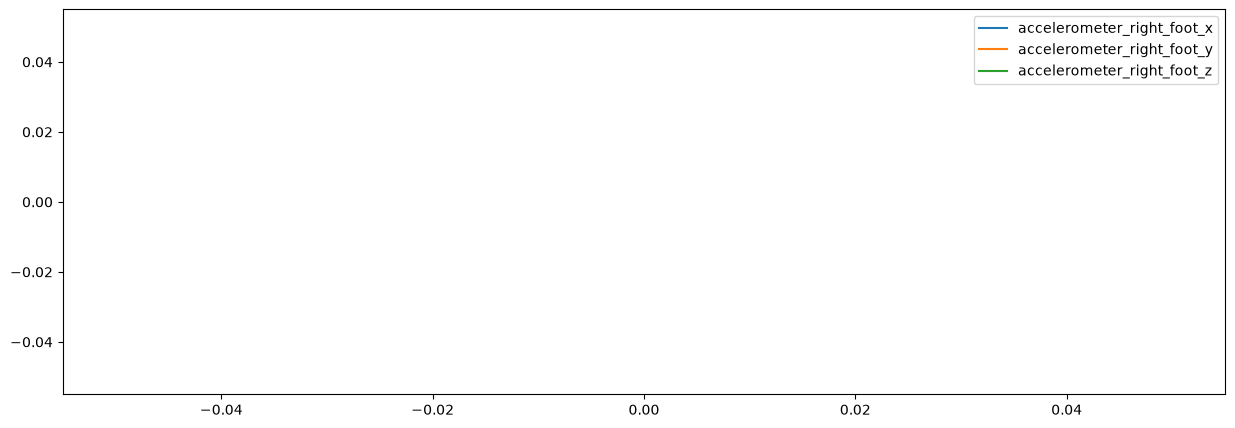

In [87]:
df[df['activity'] == 'walking'].iloc[:100].plot(y=['accelerometer_right_foot_x', 'accelerometer_right_foot_y', 'accelerometer_right_foot_z'], figsize=(15, 5))

In [89]:
print(f"Размер датасета: {df.shape}")

print(f"Количество Nan: {df.isnull().sum().sum()}")
display(df.head())
display(df.tail())

Размер датасета: (1134843, 39)
Количество Nan: 3


,accelerometer_right_foot_x,accelerometer_right_foot_y,accelerometer_right_foot_z,gyroscope_right_foot_x,gyroscope_right_foot_y,gyroscope_right_foot_z,accelerometer_right_shin_x,accelerometer_right_shin_y,accelerometer_right_shin_z,gyroscope_right_shin_x,...,gyroscope_left_shin_z,accelerometer_left_thigh_x,accelerometer_left_thigh_y,accelerometer_left_thigh_z,gyroscope_left_thigh_x,gyroscope_left_thigh_y,gyroscope_left_thigh_z,EMG_right,EMG_left,activity
0,-7868.0,-1336.0,13400.0,-28.0,26.0,-24.0,-14920.0,-240.0,-6800.0,-6.0,...,18.0,-5696.0,2088.0,16016.0,26.0,-3.0,9.0,120.0,129.0,4.0
1,-7956.0,-1384.0,13468.0,-20.0,28.0,-22.0,-14824.0,-216.0,-6928.0,-4.0,...,12.0,-5608.0,2224.0,16184.0,20.0,-3.0,7.0,120.0,128.0,4.0
2,-7892.0,-1348.0,13492.0,-18.0,24.0,-26.0,-14816.0,-144.0,-6808.0,-5.0,...,13.0,-5512.0,2168.0,16216.0,21.0,-7.0,9.0,120.0,129.0,4.0
3,-7856.0,-1352.0,13504.0,-16.0,23.0,-21.0,-14984.0,-56.0,-7200.0,-9.0,...,17.0,-5552.0,2184.0,16048.0,20.0,-3.0,4.0,121.0,128.0,4.0
4,-7896.0,-1356.0,13440.0,-13.0,26.0,-21.0,-14944.0,-280.0,-6920.0,-10.0,...,16.0,-5536.0,2032.0,16040.0,21.0,-9.0,7.0,121.0,128.0,4.0


,accelerometer_right_foot_x,accelerometer_right_foot_y,accelerometer_right_foot_z,gyroscope_right_foot_x,gyroscope_right_foot_y,gyroscope_right_foot_z,accelerometer_right_shin_x,accelerometer_right_shin_y,accelerometer_right_shin_z,gyroscope_right_shin_x,...,gyroscope_left_shin_z,accelerometer_left_thigh_x,accelerometer_left_thigh_y,accelerometer_left_thigh_z,gyroscope_left_thigh_x,gyroscope_left_thigh_y,gyroscope_left_thigh_z,EMG_right,EMG_left,activity
1137274,-5992.0,-4932.0,14792.0,146.0,-10.0,-90.0,-15936.0,240.0,-3256.0,141.0,...,-23.0,-2540.0,-2744.0,16428.0,-138.0,-76.0,426.0,125.0,126.0,4.0
1137275,-5988.0,-4996.0,14776.0,162.0,-49.0,-112.0,-16052.0,256.0,-3244.0,54.0,...,-45.0,-2560.0,-2824.0,16460.0,-111.0,-94.0,439.0,125.0,126.0,4.0
1137276,-5920.0,-4972.0,14856.0,125.0,-55.0,-120.0,-15932.0,332.0,-3196.0,-2.0,...,12.0,-2516.0,-2888.0,16280.0,-32.0,-276.0,479.0,125.0,126.0,4.0
1137277,-5968.0,-4944.0,14812.0,135.0,-76.0,-129.0,-16020.0,264.0,-3232.0,-30.0,...,59.0,-2440.0,-2868.0,16396.0,-35.0,-118.0,413.0,126.0,126.0,4.0
1137278,-5988.0,-4968.0,14800.0,106.0,-40.0,-114.0,-15928.0,308.0,-3184.0,-42.0,...,62.0,-2544.0,-2860.0,16368.0,35.0,-134.0,319.0,126.0,126.0,4.0


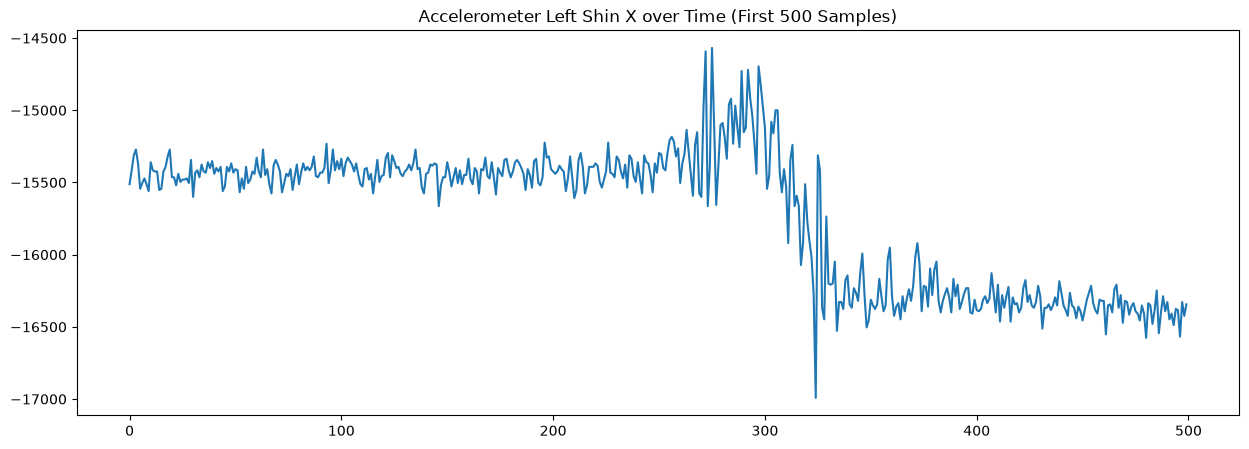

In [91]:
plt.figure(figsize=(15, 5))
plt.plot(df.iloc[:500]['accelerometer_left_shin_x'])
plt.title("Accelerometer Left Shin X over Time (First 500 Samples)")
plt.show()

In [93]:
outliers = df[(df > 32767) | (df < -32768)]
print(outliers.count())

accelerometer_right_foot_x     0
accelerometer_right_foot_y     0
accelerometer_right_foot_z     0
gyroscope_right_foot_x         0
gyroscope_right_foot_y         0
gyroscope_right_foot_z         0
accelerometer_right_shin_x     0
accelerometer_right_shin_y     0
accelerometer_right_shin_z     0
gyroscope_right_shin_x         0
gyroscope_right_shin_y         0
gyroscope_right_shin_z         0
accelerometer_right_thigh_x    0
accelerometer_right_thigh_y    0
accelerometer_right_thigh_z    0
gyroscope_right_thigh_x        0
gyroscope_right_thigh_y        0
gyroscope_right_thigh_z        0
accelerometer_left_foot_x      0
accelerometer_left_foot_y      0
accelerometer_left_foot_z      0
gyroscope_left_foot_x          0
gyroscope_left_foot_y          0
gyroscope_left_foot_z          0
accelerometer_left_shin_x      0
accelerometer_left_shin_y      0
accelerometer_left_shin_z      0
gyroscope_left_shin_x          0
gyroscope_left_shin_y          0
gyroscope_left_shin_z          0
accelerome

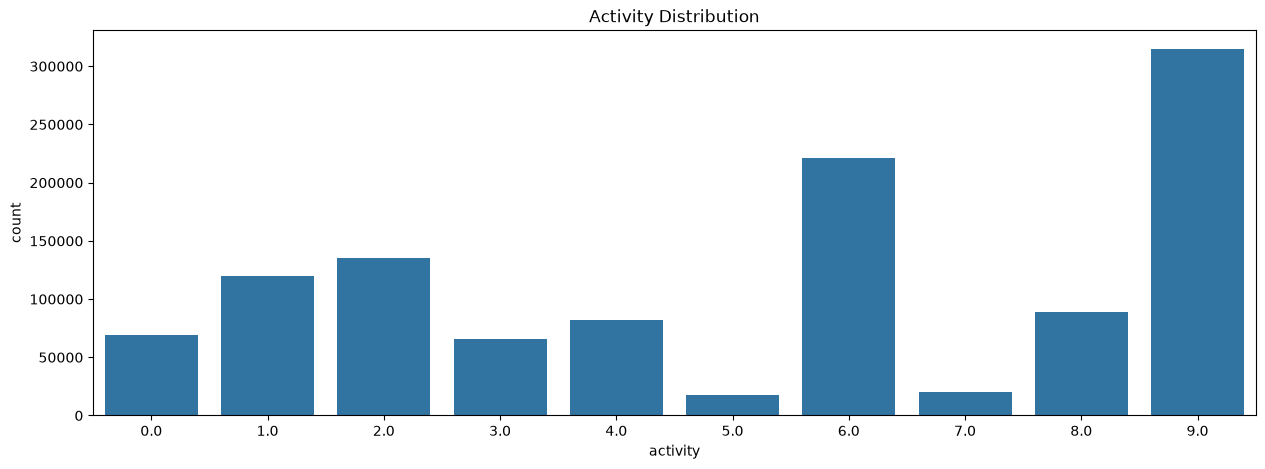

In [95]:
plt.figure(figsize=(15, 5))
sns.countplot(x='activity', data=df)
plt.title("Activity Distribution")
plt.show()

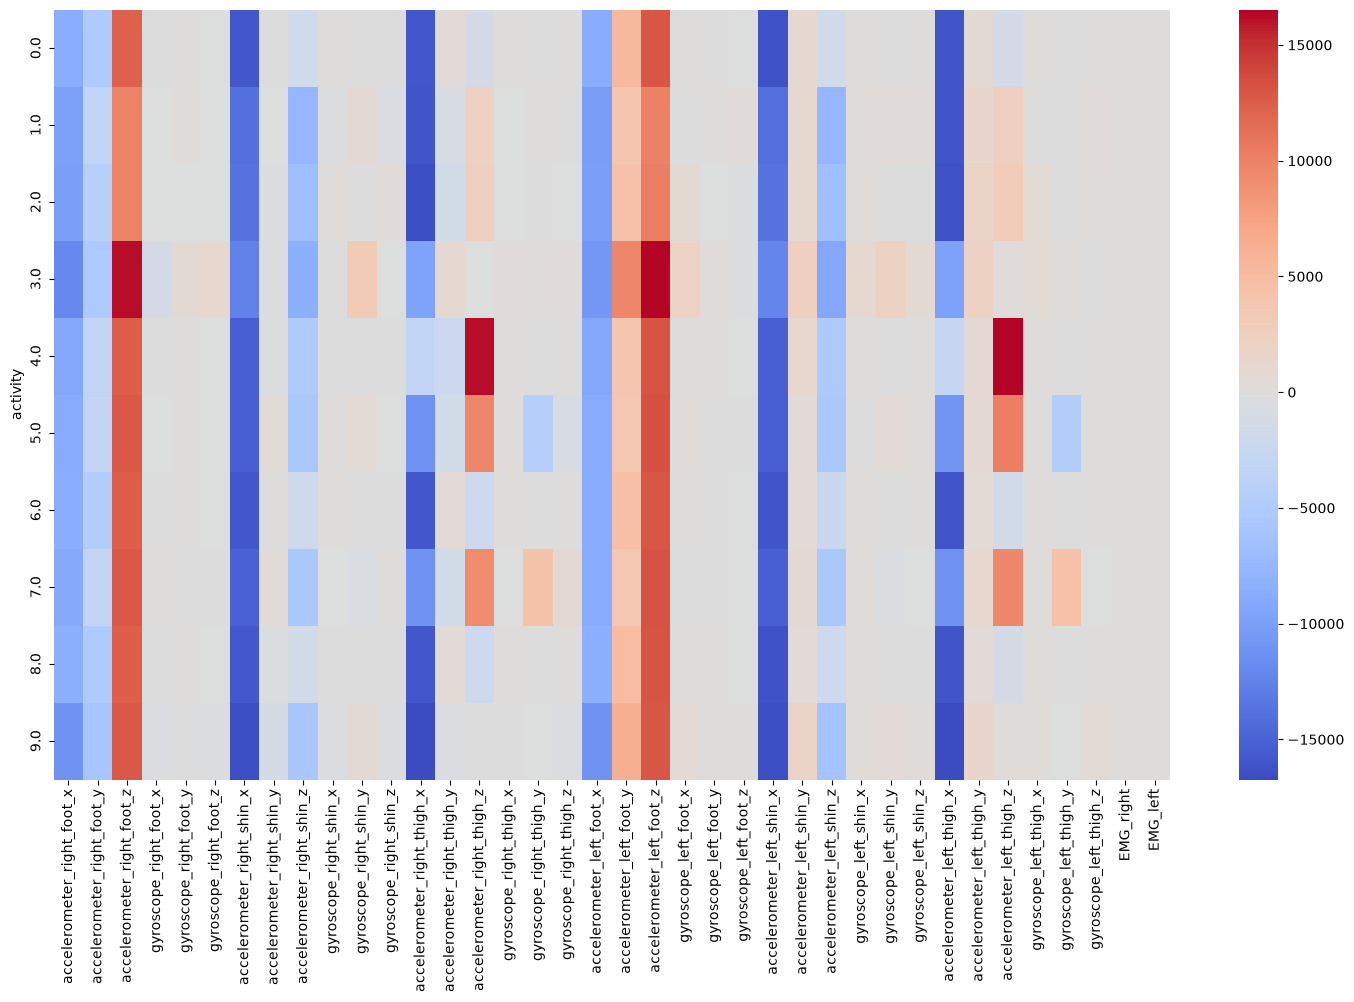

In [97]:
summary = (df.groupby('activity').mean(numeric_only=True))

plt.figure(figsize=(18, 10))
sns.heatmap(summary, cmap="coolwarm")
plt.show()

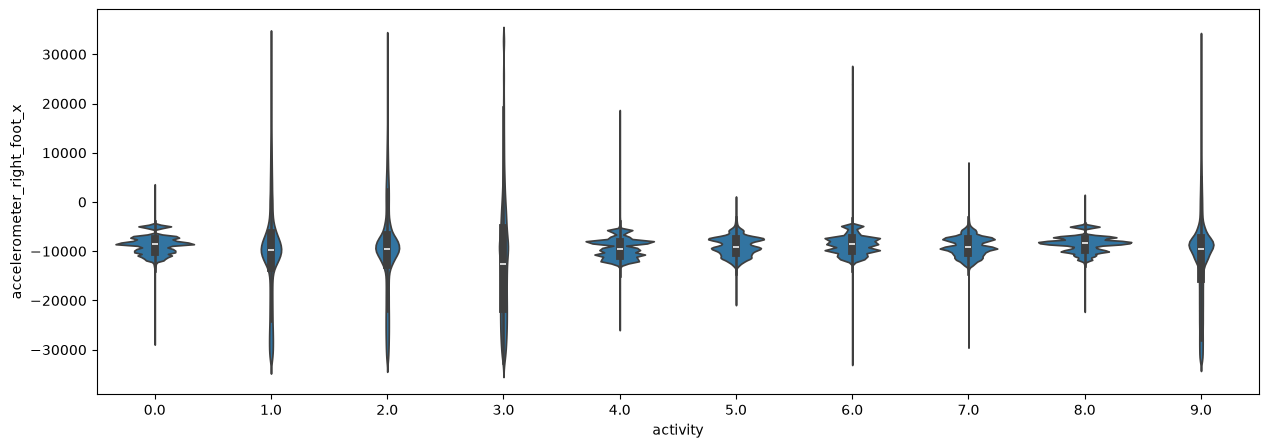

In [98]:
plt.figure(figsize=(15, 5))
sns.violinplot(x='activity', y='accelerometer_right_foot_x', data=df)
plt.show()